In [8]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
%matplotlib inline
import ipywidgets as widgets
from ipywidgets import interact, interactive, fixed, interact_manual
# import nbinteract as nbi

sns.set()
sns.set_context('talk')
np.set_printoptions(threshold=20, precision=2, suppress=True)
pd.options.display.max_rows = 7
pd.options.display.max_columns = 8
pd.set_option('precision', 2)
# This option stops scientific notation for pandas
# pd.set_option('display.float_format', '{:.2f}'.format)

# Bootstrapping for Linear Regression (Inference for the True Coefficients)

Recall that in linear regression, we fit a model of the following form
$$
\begin{aligned}
f_\hat{\theta} (x) = \hat{\theta_0} + \hat{\theta_1} x_1 + \ldots + \hat{\theta_p} x_p
\end{aligned}
$$

We would like to infer the true coefficients of the model. Since the $\hat{\theta_0}$, $\hat{\theta_1}$, $\ldots$ $\hat{\theta_p}$ are estimators that vary based on our training data/observations, we would like to understand how our estimated coefficients compare with the true coefficients. Bootstrapping is a *nonparametric* approach to statistical inference that gives us standard errors and confidence intervals for our parameters. 

Let's take a look at an example of how we use bootstrapping methods within linear regression. 


## The Data

Otis Dudley Duncan was a quantitative sociologist interested in measuring the prestige levels of different occupations. There were only 90 occupations that were rated for their prestige level in the 1947 National Opinion Research Center (NORC) survey. Duncan wanted to “fill in” prestige scores for unrated occupations by using income and education data about each occupation recorded by the 1950 census. When joining the NORC data with the 1950 census data, only 45 occupations could be matched. Ultimately, Duncan's goal was to create a model to explain prestige using different characteristics; using this model, one can predict the prestige of other occupations not recorded in the NORC survey.

The Duncan dataset is a random sample of that contains information on the prestige and other characteristics of 45 U. S. occupations in 1950. 
The variables are:

`occupation` represents the type of occupation/title.

`income` represents the percentage of occupational incumbents who earned incomes in excess of $3,500.

`education` represents the percentage of incumbents in the occupation in the 1950 U.S. Census who were high school graduates.

`prestige` represents the percentage of respondents in a survey who rated an occupation as “good” or “excellent” in prestige.






In [9]:
duncan = pd.read_csv('duncan.csv').loc[:, ["occupation", "income", "education", "prestige"]]
duncan

,occupation,income,education,prestige
0,accountant,62,86,82
1,pilot,72,76,83
2,architect,75,92,90
...,...,...,...,...
42,janitor,7,20,8
43,policeman,34,47,41
44,waiter,8,32,10


It is usually a good idea to explore the data through visualization in order to gain an understanding of the relationships between your variables. Below, we will visualize the correlations between income, educationa and prestige.

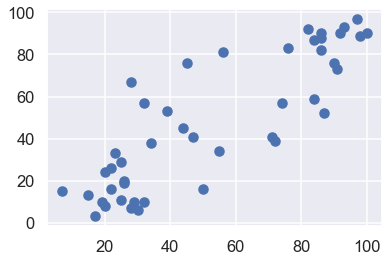

In [10]:
plt.scatter(x=duncan["education"], y=duncan["prestige"])

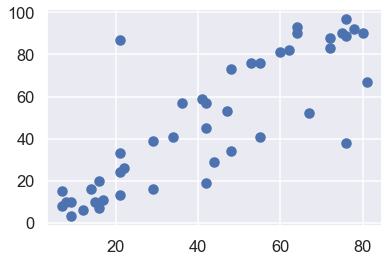

In [11]:
plt.scatter(x=duncan["income"], y=duncan["prestige"])

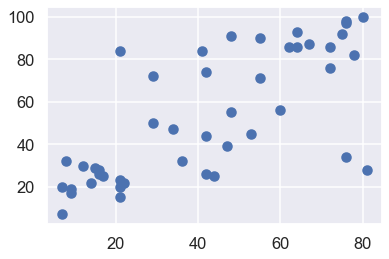

In [12]:
plt.scatter(x=duncan["income"], y=duncan["education"])

From the plots above, we see that both education and income are positively correlated with prestige; hence, both of these variables might be useful in helping explain prestige. Let's fit a linear model using these explanatory variables to explain prestige.

## Fitting the model 

We will fit the following model, that explains the prestige of an occupation as a linear function of income and education:

$$
\begin{aligned}
\texttt{prestige}_i
= \theta_0^* 
+ \theta_\texttt{income}^*\cdot\texttt{income}_i
+ \theta_\texttt{education}^*\cdot\texttt{education}_i
+ \varepsilon_i
\end{aligned}
$$

In order to fit this model, we will define the design matrix (X) and our response variable (y):

In [ ]:
X = duncan.loc[:, ["income", "education"]]
X.head()

In [10]:
y = duncan.loc[:, "prestige"]
y.head()

0    82
1    83
2    90
3    76
4    90
Name: prestige, dtype: int64

Below, we fit our linear model and print all the $\widehat \theta$ coefficients of the model (from the equation above) after the model has been fit to the data. Note that these are our sample coefficients.

In [11]:
import sklearn.linear_model as lm

linear_model = lm.LinearRegression()
linear_model.fit(X, y)

print("""
intercept: %.2f
income:    %.2f
education:    %.2f
""" % (tuple([linear_model.intercept_]) + tuple(linear_model.coef_)))


intercept: -6.06
income:    0.60
education:    0.55



The coefficients above give us an estimate of the true coefficients. But had our sample data been different, we would have fit our model to different data, causing these coefficients to be different. We would like to explore what our coefficients might have been using bootstrapping methods.

In our bootstrapping methods and analysis, we will focus on the coefficient of education. We would like to explore the partial relationship between prestige and education holding income constant (rather than the marginal relationship between prestige and education ignoring income). The partial regression coefficient $\widehat\theta_\texttt{education}$ illustrates the partial relationship between prestige and education within our data. 

## Bootstrapping the Observations 

In this method, we consider the pairs $(X_i, y_i)$ to be our sample, so we construct the bootstrap resample by sampling with replacement from these pairs:

$$
\begin{aligned}
(X_i^*, y_i^*) 
= (X_I, y_I), \text{ where } I=1,\dots,n \text{ is sampled uniformly at random.}
\end{aligned}
$$

In other words, we sample n observations with replacement from our data points; this is our bootstrap sample. Then we will fit a new linear regression model to this sampled data and record the education coefficient $\tilde\theta_\texttt{education}$; this coefficient is our bootstrap statistic.

In [50]:
def simple_resample(n): 
    return(np.random.randint(low = 0, high = n, size = n))

def bootstrap(boot_pop, statistic, resample = simple_resample, replicates = 10000):
    n = len(boot_pop)
    resample_estimates = np.array([statistic(boot_pop[resample(n)]) for _ in range(replicates)])
    return resample_estimates

In [51]:
def educ_coeff(data_array):
    X = data_array[:, 1:]
    y = data_array[:, 0]
    
    linear_model = lm.LinearRegression()
    model = linear_model.fit(X, y)
    theta_educ = model.coef_[1]

    return theta_educ

data_array = duncan.loc[:, ["prestige", "income", "education"]].values

theta_hat_sampling = bootstrap(data_array, educ_coeff)

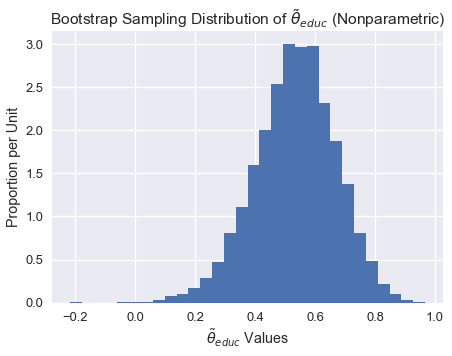

In [57]:
plt.figure(figsize = (7, 5))
plt.hist(theta_hat_sampling, bins = 30, normed = True)
plt.xlabel("$\\tilde{\\theta}_{educ}$ Values")
plt.ylabel("Proportion per Unit")
plt.title("Bootstrap Sampling Distribution of $\\tilde{\\theta}_{educ}$ (Nonparametric)");
plt.show()


Notice how the sampling distribution above is slightly skewed to the left. 

### Estimating the True Coefficients

Although we cannot directly measure $\theta^*_\texttt{education}$ we can use a bootstrap confidence interval to account for variability in the sample regression coefficient $\widehat\theta_{\texttt{education}}$. Below, We construct an approximate 95% confidence interval for the true coefficient $\theta^*_\texttt{education}$, using the bootstrap percentile method. The confidence interval extends from the 2.5th percentile to the 97.5th percentile of the 10,000 bootstrapped coefficients.

In [52]:
left_confidence_interval_endpoint = np.percentile(theta_hat_sampling, 2.5)
right_confidence_interval_endpoint = np.percentile(theta_hat_sampling, 97.5)

left_confidence_interval_endpoint, right_confidence_interval_endpoint

(0.24714198882974781, 0.78293602739856061)

From the confidence interval above, we are fairly certain that the true coefficient lies between 0.236 and 0.775.

## Confidence Interval Using Normal Theory

We can also create confidence intervals based on normal theory. Since the $\widehat \theta_{educ}$ values appear normally distributed, we can construct a confidence interval using by computing the following:

$$
\begin{aligned}
[\widehat \theta - z_{\frac{\alpha}{2}}*SE(\theta^*),  \widehat \theta + z_{\frac{\alpha}{2}}*SE(\theta^*)]
\end{aligned}
$$

where $SE(\theta^*)$ is the standard error of our bootstrapped coefficients, $z$ is a constant, and $\widehat \theta$ is our sample coefficient. Note that $z$ varies depending on the confidence level of the interval we are constructing. Since we are creating a 95% confidence interval, we will use 1.96.

In [55]:
# We will use the statsmodels library in order to find the standard error of the coefficients
import statsmodels.api as sm
ols = sm.OLS(y, X)
ols_result = ols.fit()
# Now you have at your disposition several error estimates, e.g.
ols_result.HC0_se

income       0.15
education    0.12
dtype: float64

In [56]:
left_confidence_interval_endpoint_normal = 0.55 - (1.96*0.12)
right_confidence_interval_endpoint_normal = 0.55 + (1.96*0.12)
left_confidence_interval_endpoint_normal, right_confidence_interval_endpoint_normal

(0.3148000000000001, 0.7852)

**Observations: **
Notice how the confidence interval using normal theory is more narrow than the confidence interval using the percentile method, especially towards the left of the interval.

